# Stage 7: SHAP explainability

Results of `python -m src.explain`, for the best GBM of each horizon.

**What is a SHAP value?** For one forecast, it is the share of the forecast that one feature is
responsible for. Base value + all SHAP values = the forecast. The mean absolute SHAP value of a feature
over many rows is its global importance. Units: power / rated.

**Can we trust the explanations?** That is what the stability section tests: if the importance ranking
changed a lot between stations, seasons or retrained models, it would say little about the problem.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

## 1. Global importance

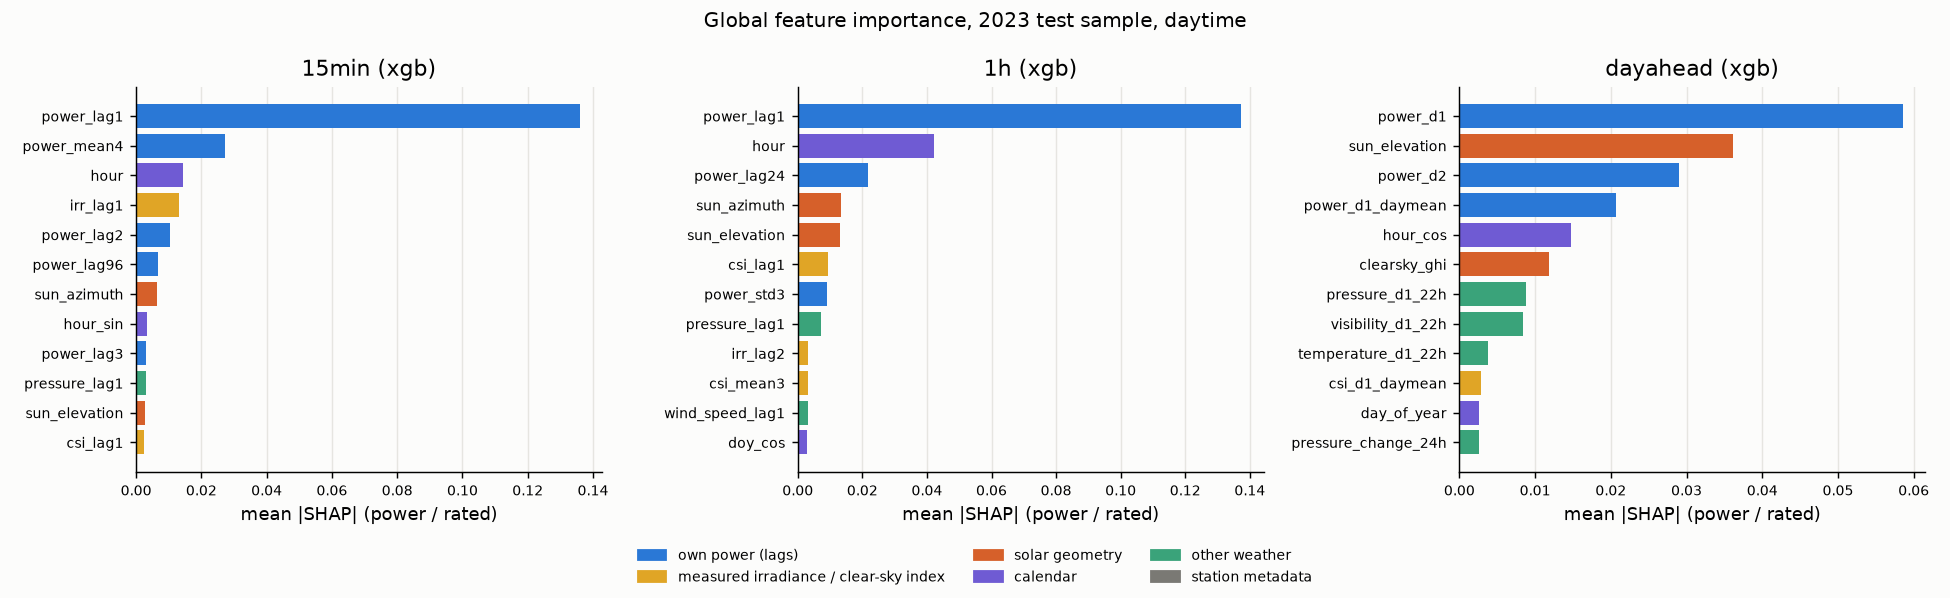

In [2]:
Image(FIGURES + "07_shap_global.png")

In [3]:
imp = pd.read_csv(TABLES + "07_shap_importance.csv")
imp[imp["rank"] <= 8][["horizon", "model", "rank", "feature", "group", "share_pct"]].round(2)

,horizon,model,rank,feature,group,share_pct
0,15min,xgb,1,power_lag1,own power (lags),54.08
1,15min,xgb,2,power_mean4,own power (lags),10.88
2,15min,xgb,3,hour,calendar,5.75
3,15min,xgb,4,irr_lag1,measured irradiance / clear-sky index,5.23
4,15min,xgb,5,power_lag2,own power (lags),4.12
5,15min,xgb,6,power_lag96,own power (lags),2.65
6,15min,xgb,7,sun_azimuth,solar geometry,2.55
7,15min,xgb,8,hour_sin,calendar,1.32
32,1h,xgb,1,power_lag1,own power (lags),48.38
33,1h,xgb,2,hour,calendar,14.86


## 2. Grouped importance
Lagged power and lagged irradiance are strongly correlated, so SHAP splits their shared credit between
them. Summing the importance per feature group is more robust than reading single features.

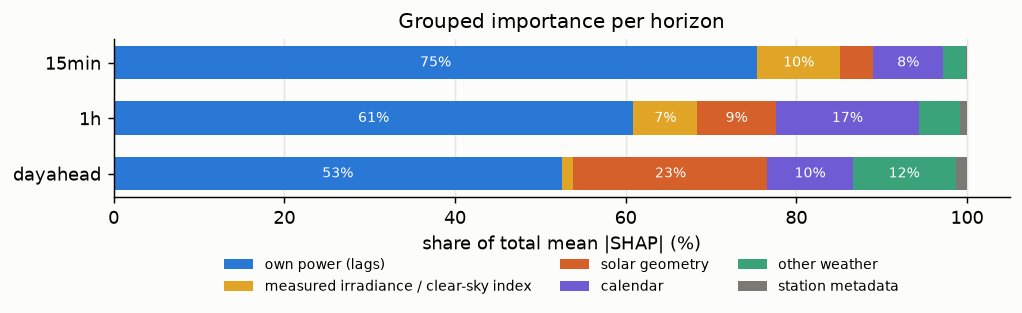

In [4]:
Image(FIGURES + "07_shap_groups.png")

In [5]:
groups = pd.read_csv(TABLES + "07_shap_groups.csv")
groups.pivot(index="group", columns="horizon", values="share_pct").round(1)

horizon,15min,1h,dayahead
group,,,
calendar,8.3,16.7,10.0
measured irradiance / clear-sky index,9.7,7.5,1.4
other weather,2.7,4.9,12.1
own power (lags),75.4,60.9,52.5
solar geometry,3.9,9.2,22.7
station metadata,0.1,0.8,1.3


## 3. Stability
Spearman rank correlation between importance vectors (1 = the same ranking). `top5_overlap` is the mean
share of the top-5 features that two vectors have in common.

In [6]:
pd.read_csv(TABLES + "07_shap_stability.csv").round(3)

,horizon,across,n_groups,mean_spearman,min_spearman,top5_overlap,commit
0,15min,stations,24,0.993,0.964,1.00,88e77df
1,15min,seasons,4,0.974,0.962,1.00,88e77df
2,15min,retrained models (bootstrap + seed),5,0.983,0.969,0.92,88e77df
3,1h,stations,43,0.988,0.953,1.00,88e77df
4,1h,seasons,4,0.981,0.968,1.00,88e77df
5,1h,retrained models (bootstrap + seed),5,0.990,0.983,1.00,88e77df
6,dayahead,stations,43,0.981,0.918,1.00,88e77df
7,dayahead,seasons,4,0.953,0.912,1.00,88e77df
8,dayahead,retrained models (bootstrap + seed),5,0.966,0.942,0.92,88e77df


## 4. Physical expectations (hypotheses, not conclusions)
For each feature: does a higher value push the forecast in the expected direction? The correlation
between the feature value and its SHAP value gives the direction.

In [7]:
pd.read_csv(TABLES + "07_physical_checks.csv").round(3)

,horizon,feature,expected_direction,spearman_value_vs_shap,agrees,mean_abs_shap,commit
0,15min,power_lag1,+,0.997,True,0.136,88e77df
1,15min,irr_lag1,+,0.937,True,0.013,88e77df
2,15min,csi_lag1,+,0.175,True,0.002,88e77df
3,15min,clearsky_ghi,+,0.836,True,0.001,88e77df
4,15min,sun_elevation,+,0.869,True,0.003,88e77df
5,15min,temperature_lag1,-,0.704,False,0.002,88e77df
6,1h,power_lag1,+,0.989,True,0.137,88e77df
7,1h,irr_lag1,+,0.388,True,0.002,88e77df
8,1h,csi_lag1,+,0.813,True,0.009,88e77df
9,1h,clearsky_ghi,+,NaN,not used by the model,0.000,88e77df


## 5. Dependence plots (1 h)

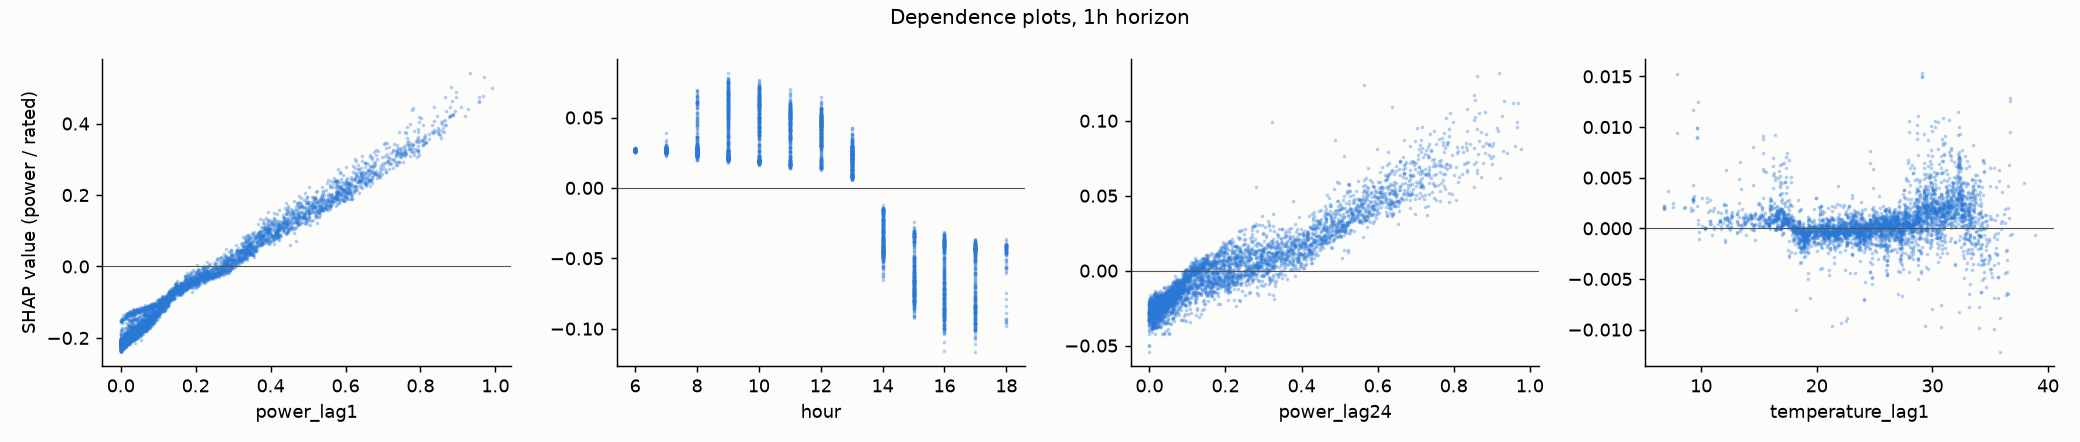

In [8]:
Image(FIGURES + "07_shap_dependence_1h.png")

## 6. Local explanations (1 h)
Three single forecasts: a clear hour, a cloudy midday hour and a ramp.

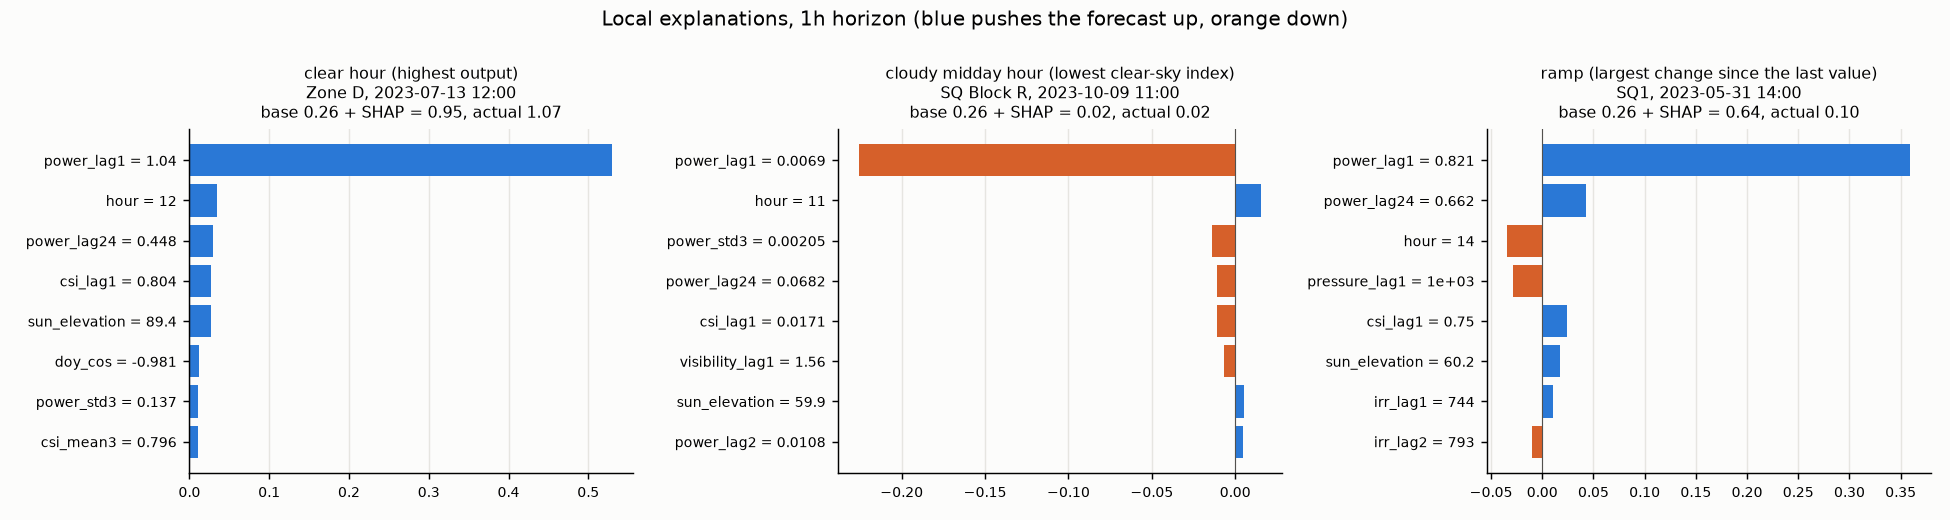

In [9]:
Image(FIGURES + "07_shap_local_1h.png")